## Bibliotecas

In [ ]:
pip install fitter

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 48.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.9/71.9 kB 2.1 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstal

In [ ]:
# Para solucionar el error de dependencias provocado por la instalación de fitter:
# 1. Ejecuta esta celda para restaurar numpy y pandas compatibles.
# 2. Reinicia el entorno de ejecución en el menú: Entorno de ejecución -> Reiniciar sesión (Runtime -> Restart session).
# 3. Vuelve a importar las librerías.

!pip install "numpy<2.3" "pandas==2.2.3" --force-reinstall

from fitter import Fitter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Generador de valores random
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

  Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached pandas-2.2.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (89 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached pytz-2026.4-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2026.4-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached pandas-2.2.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.7 MB)
Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.5 MB)
Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl (229 kB)
Using cached pytz-2026.4-py2.py3-none-any.whl (506 kB)
Using cached tzdata-2026.4-py2.py3-none-any.whl (347 kB)
Using cached six-1.17.0-py2.py3-none-any.whl (11 kB)
  Attempting uninstall: pytz
    Found existing installation: pytz 2026.4
    Uninstalli

In [ ]:
import statsmodels.api as sm

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Carga de Datos

In [ ]:
import glob
# Buscar el CSV dentro de la carpeta "TP 4 - Grupo 6"
archivos = glob.glob(
    "/content/drive/**/Simulación - Grupo 6/dataset-uber_lyft.csv",
    recursive=True
)

if not archivos:
    raise FileNotFoundError("No se encontró dataset-uber_lyft.csv")

ruta = archivos[0]

viajes = pd.read_csv(ruta)

In [ ]:
#Otra opción
#ruta = "/content/drive/MyDrive/dataset-uber_lyft.csv"
#viajes = pd.read_csv(ruta)

## Análisis Exploratorio de Datos

In [ ]:
#Mostrar el tip de dato
type(viajes)

pandas.core.frame.DataFrame

In [ ]:
#Mostrar primeros registros
viajes.head()

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,1.544953e+09,9,16,12,2018-12-16 09:30:07,America/New_York,Haymarket Square,North Station,Lyft,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,4bd23055-6827-41c6-b23b-3c491f24e74d,1.543284e+09,2,27,11,2018-11-27 02:00:23,America/New_York,Haymarket Square,North Station,Lyft,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,1.543554e+09,4,30,11,2018-11-30 04:53:02,America/New_York,Haymarket Square,North Station,Lyft,...,0.0000,1543507200,34.67,1543550400,45.03,1543510800,30.30,1543550400,38.53,1543510800
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,1.543463e+09,3,29,11,2018-11-29 03:49:20,America/New_York,Haymarket Square,North Station,Lyft,...,0.0001,1543420800,33.10,1543402800,42.18,1543420800,29.11,1543392000,35.75,1543420800


In [ ]:
# Dimensiones del DF
print("Filas | Columnas")
print(viajes.shape)

print("\nInformación")
print(viajes.info())


Filas | Columnas
(693071, 57)

Información
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693071 entries, 0 to 693070
Data columns (total 57 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           693071 non-null  object 
 1   timestamp                    693071 non-null  float64
 2   hour                         693071 non-null  int64  
 3   day                          693071 non-null  int64  
 4   month                        693071 non-null  int64  
 5   datetime                     693071 non-null  object 
 6   timezone                     693071 non-null  object 
 7   source                       693071 non-null  object 
 8   destination                  693071 non-null  object 
 9   cab_type                     693071 non-null  object 
 10  product_id                   693071 non-null  object 
 11  name                         693071 non-null  object 
 12  price          

In [ ]:
# Verficar faltante
print(viajes.isnull().sum())
#ojo: la columna price

id                                 0
timestamp                          0
hour                               0
day                                0
month                              0
datetime                           0
timezone                           0
source                             0
destination                        0
cab_type                           0
product_id                         0
name                               0
price                          55095
distance                           0
surge_multiplier                   0
latitude                           0
longitude                          0
temperature                        0
apparentTemperature                0
short_summary                      0
long_summary                       0
precipIntensity                    0
precipProbability                  0
humidity                           0
windSpeed                          0
windGust                           0
windGustTime                       0
v

# Preparación de datos

In [ ]:
viajes['cab_type'].value_counts()

,count
cab_type,
Uber,385663
Lyft,307408


# Filtro por Lyft

In [ ]:
viajes_Lyft = viajes[viajes['cab_type'] == 'Lyft']
lyft_std = viajes_Lyft[(viajes_Lyft['name'] == 'Lyft') & (viajes_Lyft['surge_multiplier'] == 1.0)].copy()

In [ ]:
list(viajes_Lyft.columns)
list(lyft_std.columns)

['id',
 'timestamp',
 'hour',
 'day',
 'month',
 'datetime',
 'timezone',
 'source',
 'destination',
 'cab_type',
 'product_id',
 'name',
 'price',
 'distance',
 'surge_multiplier',
 'latitude',
 'longitude',
 'temperature',
 'apparentTemperature',
 'short_summary',
 'long_summary',
 'precipIntensity',
 'precipProbability',
 'humidity',
 'windSpeed',
 'windGust',
 'windGustTime',
 'visibility',
 'temperatureHigh',
 'temperatureHighTime',
 'temperatureLow',
 'temperatureLowTime',
 'apparentTemperatureHigh',
 'apparentTemperatureHighTime',
 'apparentTemperatureLow',
 'apparentTemperatureLowTime',
 'icon',
 'dewPoint',
 'pressure',
 'windBearing',
 'cloudCover',
 'uvIndex',
 'visibility.1',
 'ozone',
 'sunriseTime',
 'sunsetTime',
 'moonPhase',
 'precipIntensityMax',
 'uvIndexTime',
 'temperatureMin',
 'temperatureMinTime',
 'temperatureMax',
 'temperatureMaxTime',
 'apparentTemperatureMin',
 'apparentTemperatureMinTime',
 'apparentTemperatureMax',
 'apparentTemperatureMaxTime']

In [ ]:
viajes_Lyft.head()
lyft_std.head()

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
11,d859ec69-b3ff-4af8-9abd-441e31430c94,1.543433e+09,19,28,11,2018-11-28 19:23:07,America/New_York,Back Bay,Northeastern University,Lyft,...,0.0000,1543420800,33.82,1543399200,42.72,1543438800,30.19,1543399200,36.75,1543438800
21,5ef44fdf-c5d3-4d07-967a-a8710e537e74,1.545133e+09,11,18,12,2018-12-18 11:35:05,America/New_York,North Station,Haymarket Square,Lyft,...,0.0028,1545152400,23.09,1545192000,38.03,1545109200,11.82,1545134400,31.92,1545109200
33,174b960d-58f1-4dfd-8672-8b43f13726a7,1.543775e+09,18,2,12,2018-12-02 18:23:07,America/New_York,North Station,Northeastern University,Lyft,...,0.0894,1543770000,36.40,1543726800,50.94,1543788000,35.78,1543748400,50.27,1543788000
45,104ced5c-1c1b-4021-94bb-b21af453399a,1.544963e+09,12,16,12,2018-12-16 12:30:14,America/New_York,North Station,South Station,Lyft,...,0.1246,1544979600,38.94,1544954400,43.78,1544990400,33.76,1545019200,38.39,1544986800


In [ ]:
print(viajes_Lyft.shape)
print(viajes_Lyft.isnull().sum())

print(lyft_std.shape)
print(lyft_std.isnull().sum())

(307408, 57)
id                             0
timestamp                      0
hour                           0
day                            0
month                          0
datetime                       0
timezone                       0
source                         0
destination                    0
cab_type                       0
product_id                     0
name                           0
price                          0
distance                       0
surge_multiplier               0
latitude                       0
longitude                      0
temperature                    0
apparentTemperature            0
short_summary                  0
long_summary                   0
precipIntensity                0
precipProbability              0
humidity                       0
windSpeed                      0
windGust                       0
windGustTime                   0
visibility                     0
temperatureHigh                0
temperatureHighTime           

In [ ]:
print(viajes_Lyft["timestamp"].value_counts().head(6))
print(lyft_std["timestamp"].value_counts().head(6))

timestamp
1.545000e+09    203
1.543424e+09    101
1.543439e+09     96
1.543419e+09     94
1.543440e+09     88
1.543444e+09     88
Name: count, dtype: int64
timestamp
1.545000e+09    36
1.543419e+09    18
1.543426e+09    18
1.543416e+09    17
1.543435e+09    17
1.543441e+09    17
Name: count, dtype: int64


In [ ]:
viajes_Lyft.dtypes
lyft_std.dtypes

,0
id,object
timestamp,float64
hour,int64
day,int64
month,int64
datetime,object
timezone,object
source,object
destination,object
cab_type,object


,sumsquare_error,aic,bic,kl_div,ks_statistic,ks_pvalue
lognorm,0.091394,166398.383066,166424.915601,0.079191,0.078478,6.671156e-275
johnsonsb,0.096684,166931.059577,166966.436290,0.083784,0.083581,8.158038e-312
gamma,0.122003,171208.308731,171234.841265,0.108199,0.099943,0.000000e+00
norm,0.241796,192471.201706,192488.890062,0.272690,0.157070,0.000000e+00
weibull_min,0.283178,189943.863678,189970.396213,0.352254,0.162160,0.000000e+00


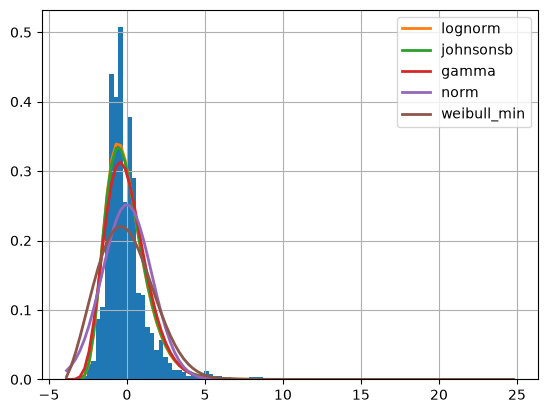

In [ ]:
#Cálculo de la distancia teniendo en cuenta solamente los viajes en categoría estándar
# 2. Regresión Lineal del precio en función de la distancia
X = lyft_std['distance']
X = sm.add_constant(X) # Agrega la ordenada al origen
y = lyft_std['price']

modelo = sm.OLS(y, X).fit()
# print(modelo.summary()) # Para ver los coeficientes beta_0 y beta_1

# 3. Extraer los residuos del modelo
lyft_std['residuos'] = modelo.resid

# 4. Ajustar la FDP exclusivamente sobre los residuos
distribuciones_comunes = ['norm', 'johnsonsb', 'gamma', 'lognorm', 'weibull_min']
fdp_residuos = Fitter(lyft_std['residuos'], distributions=distribuciones_comunes)
fdp_residuos.fit()
fdp_residuos.summary()

#Gráfico de la distribución del residuo

# Intervalo entre arribos de Lyft

array([[<Axes: title={'center': 'timestamp'}>]], dtype=object)

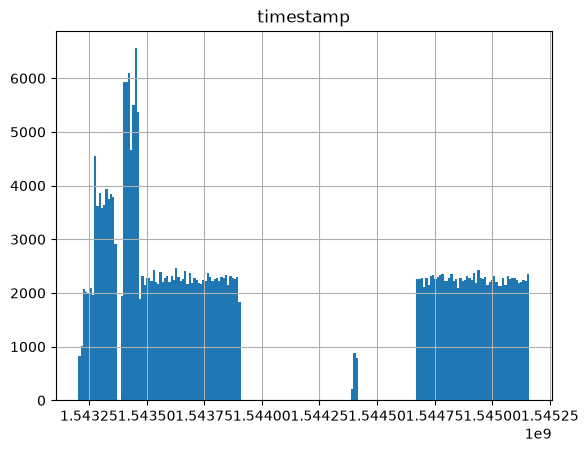

In [ ]:
lyft.hist('timestamp', bins=200)

*Cálculo* de FDP


In [ ]:
#calculo IA
# IA: exponencial con media 2,5 min. NO usar timestamp.diff() (mide el ritmo del script, no la demanda)
MEDIA_IA_BASE = 2.5
FACTOR_DEMANDA = {"Actual": 1.0, "Peor (+30%)": 1.3, "Mejor (-30%)": 0.7}
# metodo para la simulacion
def sortear_IA(escenario="Actual", n=31000):
    media = MEDIA_IA_BASE / FACTOR_DEMANDA[escenario]
    return rng.exponential(scale=media, size=n)



In [ ]:
lyft["IA_Actual"] = sortear_IA("Actual", len(lyft))
lyft["IA_Peor"] = sortear_IA("Peor (+30%)", len(lyft))
lyft["IA_Mejor"] = sortear_IA("Mejor (-30%)", len(lyft))

Actual        media = 2.48 min | min = 0.0001 | max = 32.9
Peor (+30%)   media = 1.94 min | min = 0.0000 | max = 18.6
Mejor (-30%)  media = 3.59 min | min = 0.0000 | max = 41.2


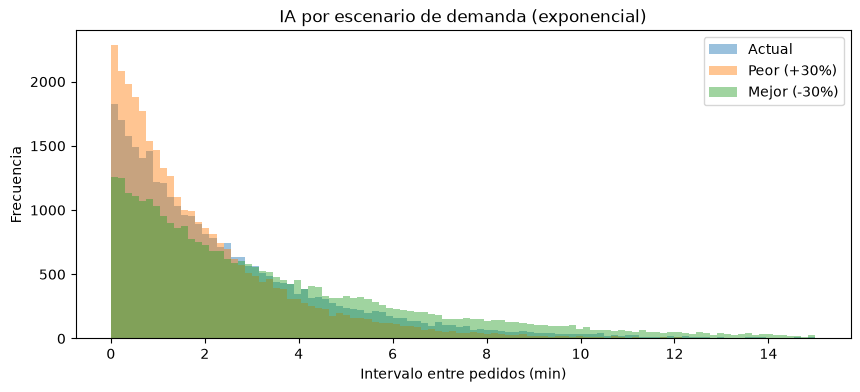

In [ ]:
plt.figure(figsize=(10, 4))
for esc in FACTOR_DEMANDA:
    x = sortear_IA(esc)
    print(f"{esc:13s} media = {x.mean():.2f} min | min = {x.min():.4f} | max = {x.max():.1f}")
    plt.hist(x, bins=100, range=(0, 15), alpha=0.45, label=esc)
plt.title("IA por escenario de demanda (exponencial)")
plt.xlabel("Intervalo entre pedidos (min)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

# Distancia

In [ ]:
distancia=lyft_dist
print(distancia['distance'].describe())

count    131232.000000
mean          2.190754
std           1.087395
min           0.390000
25%           1.270000
50%           2.150000
75%           2.980000
max           6.330000
Name: distance, dtype: float64


,sumsquare_error,aic,bic,kl_div,ks_statistic,ks_pvalue
weibull_min,1.719609,376760.177182,376789.531348,0.363563,0.072846,0.0
gamma,1.786110,381361.009688,381390.363854,0.397530,0.084494,0.0
lognorm,1.826364,384004.392707,384033.746873,0.384728,0.076565,0.0


Mejor por BIC: weibull_min (np.float64(1.7369116327905525), np.float64(0.3309934599319153), np.float64(2.083267038112721))


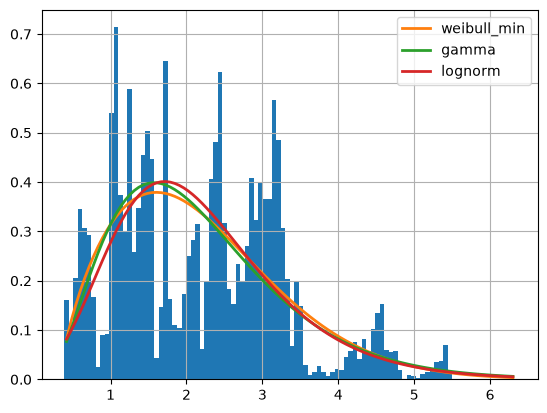

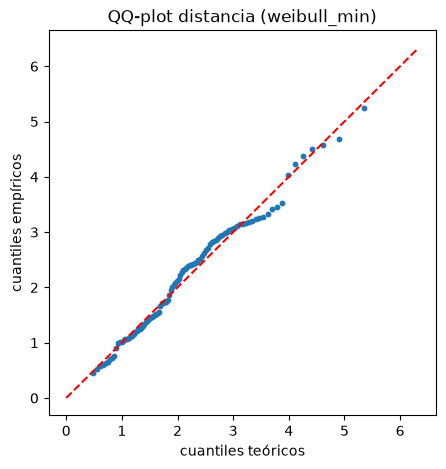

In [ ]:
# Solo familias con soporte positivo
FAMILIAS_DIST = ['lognorm', 'gamma', 'weibull_min']
fdp_distancia = Fitter(lyft_dist['distance'].values, distributions=FAMILIAS_DIST)
fdp_distancia.fit()
display(fdp_distancia.summary())

mejor_dist = list(fdp_distancia.get_best(method='bic').keys())[0]
params_dist = fdp_distancia.fitted_param[mejor_dist]     # leídos del ajuste, no copiados a mano
print("Mejor por BIC:", mejor_dist, params_dist)

# QQ-plot de la mejor
q = np.linspace(0.01, 0.99, 99)
plt.figure(figsize=(5, 5))
plt.scatter(getattr(stats, mejor_dist).ppf(q, *params_dist),
            np.quantile(lyft_dist['distance'], q), s=10)
lim = [0, lyft_dist['distance'].max()]
plt.plot(lim, lim, "r--")
plt.title(f"QQ-plot distancia ({mejor_dist})")
plt.xlabel("cuantiles teóricos")
plt.ylabel("cuantiles empíricos")
plt.show()

In [ ]:
def sortear_distancia(n, modo="parametrica"):
    if modo == "empirica":
        return rng.choice(lyft_dist['distance'].values, size=n, replace=True)
    return getattr(stats, mejor_dist).rvs(*params_dist, size=n, random_state=rng)

In [ ]:
  sortear_distancia(31000,"empirica")

array([2.82, 2.84, 2.51, ..., 2.51, 3.17, 2.4 ], shape=(31000,))

array([[<Axes: title={'center': 'distance'}>]], dtype=object)

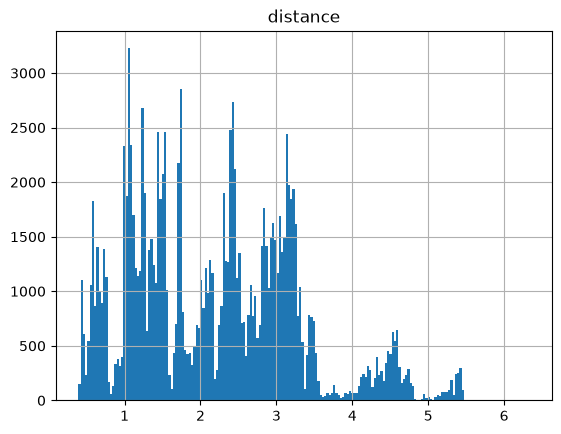

In [ ]:
distancia.hist('distance',bins=200)

*Cálculo* de FDP

,sumsquare_error,aic,bic,kl_div,ks_statistic,ks_pvalue
dgamma,1.543405,393657.298602,393686.652768,0.288198,0.092452,0.0
burr,1.596529,373237.883255,373277.022143,0.318627,0.057556,0.0
gengamma,1.641893,373606.223146,373645.362034,0.323360,0.053282,0.0
exponpow,1.642666,374077.173897,374106.528064,0.318267,0.061014,0.0
exponweib,1.643107,373657.505147,373696.644036,0.323773,0.053750,0.0


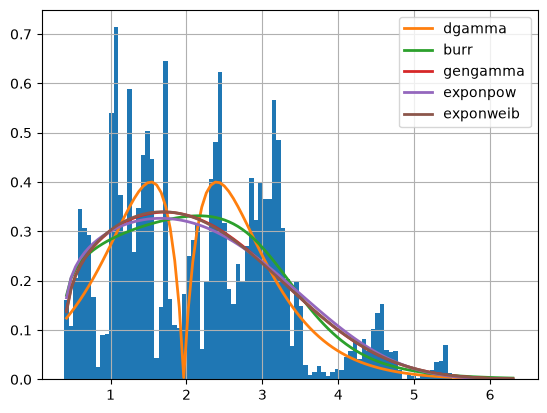

In [ ]:
"""
#Esto lo borro, dejando el cálculo con Fitter de arriba, donde solo le paso como opción
#las distribuciones que van a dar > 0 siempre.
fdp_distancia=Fitter(distancia.distance)
fdp_distancia.fit()
fdp_distancia.summary()
"""

# Duración de viaje

In [ ]:
lyft_dist['distance_km'] = lyft_dist['distance'] * 1.609

#Velocidad prmedio (21km/h) --> tp5
velocidad_media=21
desvio_velocidad=3

velocidades = np.random.normal(
    loc=velocidad_media,
    scale=desvio_velocidad,
    size=len(lyft_dist)
)
lyft_dist['duracion_min'] = (lyft_dist['distance_km'] / velocidades) * 60

In [ ]:
lyft_dist.head()

In [ ]:
lyft_dist.hist('duracion_min',bins=200)

Cálculo de FDP

In [ ]:
fdp_duracion = Fitter(lyft_dist.duracion_min)
fdp_duracion.fit()
fdp_duracion.summary()

# Tarifa

In [ ]:
lyft_std ['price'].describe()

In [ ]:
lyft_std.hist('price', bins=200)

In [ ]:
lyft_std.boxplot('price')

Cálculo de FDP

In [ ]:
fdp_tarifa = Fitter(lyft_std ['price'])
fdp_tarifa.fit()
fdp_tarifa.summary()


# Tiempo de busqueda



In [ ]:
MEDIA_BUSQ = 5.0     # min (SDD)
DESVIO_BUSQ = 1.5    # min (SDD)

def params_gamma(m, s):
    return (m / s) ** 2, 0.0, s ** 2 / m                 # a, loc, scale
def params_lognorm(m, s):
    sigma2 = np.log(1 + (s / m) ** 2)
    return np.sqrt(sigma2), 0.0, np.exp(np.log(m) - sigma2 / 2)   # s, loc, scale
# metodo para simular los valores
def sortear_busqueda(n, media=MEDIA_BUSQ, desvio=DESVIO_BUSQ, familia="gamma"):
    if familia == "gamma":
        a, loc, sc = params_gamma(media, desvio)
        x = stats.gamma.rvs(a, loc=loc, scale=sc, size=n, random_state=rng)
    else:
        sg, loc, sc = params_lognorm(media, desvio)
        x = stats.lognorm.rvs(sg, loc=loc, scale=sc, size=n, random_state=rng)
    assert (x > 0).all(), "hay valores no positivos"
    return x

 FDP

In [ ]:
plt.figure(figsize=(10, 4))
for fam in ["gamma", "lognorm"]:
    x = sortear_busqueda(31000, familia=fam)
    print(f"{fam:8s} media={x.mean():.2f} desvio={x.std():.2f} min={x.min():.2f} "
          f"p5={np.percentile(x,5):.2f} p95={np.percentile(x,95):.2f} max={x.max():.2f}")
    plt.hist(x, bins=100, alpha=0.5, label=fam, density=True)
plt.title("Tiempo de búsqueda (supuesto: media 5, desvío 1,5)")
plt.xlabel("minutos")
plt.ylabel("densidad")
plt.legend()
plt.show()

# Simulación

IA--> se calcula con el metodo de arriba

Distancia

In [ ]:
fdp_distancia.get_best(method='sumsquare_error') #menor error

In [ ]:
a = np.float64(1.9598662147932329)
loc = np.float64(1.9257140205633956)
scale = np.float64(0.46862641746854794)

In [ ]:
fdp_distancia_dgamma = stats.dgamma.rvs(a,loc=loc,scale=scale,size=31000)  #dgamma permite valores negativos pero no es la adecuada para la distancia

In [ ]:
fdp_distancia_dgamma

In [ ]:

plt.title("Histograma distancia_recorrida")
plt.xlabel("X km_recorridas")
plt.ylabel("Y cantidad_viajes")
plt.hist(fdp_distancia_dgamma, bins=200)
plt.show()

Duración

In [ ]:
fdp_duracion.get_best(method='sumsquare_error')

In [ ]:
nu = np.float64(0.7555853889270139)
loc = np.float64(1.384942470305448)
scale = np.float64(10.432735100934128)

In [ ]:
fdp_duracion_nakagami = stats.nakagami.rvs(nu, loc=loc, scale=scale, size=31000)

In [ ]:
fdp_duracion_nakagami

In [ ]:
plt.title("Histograma duracion_viaje")
plt.xlabel("X duracion")
plt.ylabel("Y cantidad_viajes")
plt.hist(fdp_duracion_nakagami, bins=200)
plt.show()

Tarifa

In [ ]:
fdp_tarifa.get_best(method='sumsquare_error')

In [ ]:
a= np.float64(2.2646116459135563)
b= np.float64(1.337298800438556)
loc= np.float64(-0.025859349952667983)
scale= np.float64(96.94179927488513)

In [ ]:
fdp_tarifa_johnsonsb=stats.johnsonsb.rvs(a,b,loc=loc,scale=scale,size=31000)

In [ ]:
fdp_tarifa_johnsonsb

In [ ]:
plt.title("Histograma tarifas")
plt.xlabel("X USD")
plt.ylabel("Y ")
plt.hist(fdp_tarifa_johnsonsb, bins=200)
plt.show()

tiempo de busqueda--> se calcula con el metodo de arriba